# Cross-analysis

The per-model notebooks (`loglinear.ipynb`, `single_hidden_layer_mlp.ipynb`, `svm.ipynb`) each look at one architecture. In this notebook we compare the architectures with each other and do some extra checks:

1. Bayesian comparison of log-linear, MLP and SVM.
2. The ROPE and why we use 0.005.
3. Repeating the cross-validation with three seeds.
4. Tuning the MLP (learning rate, hidden size).
5. A two-layer MLP, tuning the SVM's C, and the gap between the SVM's cross-validation and validation scores.
6. Whether building the tokenizers on all of train inflates the cross-validation scores.
7. The identical GloVe validation scores of log-linear and MLP.
8. Final comparison of all systems.
9. Error analysis, per-class accuracy and training time.

We use the NLTK tokenizer everywhere unless stated otherwise. It is the best tokenizer for all models in the per-model notebooks (BPE 20000 is about equal) and the only one that works with GloVe. All cross-validation uses the parent folds from the other notebooks. New results are cached in `results/` in files starting with `xa_`, so running the notebook again is fast; `RECOMPUTE = True` recomputes them.

In [1]:
SEEDS = [0, 1, 2]       # cross-validation runs; seed 0 gives the same folds as the per-model notebooks
K = 5
ROPE = 0.005            # motivated in section 2
TOK = "nltk"
FEATURES = ["indicator", "bow", "glove"]
MODELS = ["loglinear", "mlp", "svm_linear"]
TOKENIZERS = ["nltk", "bpe_500", "bpe_2000", "bpe_8000", "bpe_20000"]
MAX_ITER = 500          # log-linear, as in loglinear.ipynb
ORIGINAL_MLP = dict(hidden_dim=32, dropout=0.3, batch_size=64, learning_rate=1e-4, weight_decay=1e-2, num_epochs=10)
RECOMPUTE = False

In [2]:
import json
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import cv_helpers as cv
from from_tutorial import analysis
from tokenized_data import load

pd.set_option("display.width", 200)

splits, tokenizer = load(TOK)
train, validation = splits["train"], splits["validation"]
y, y_val = train.label.to_numpy(), validation.label.to_numpy()
raw_text = load("bpe_500")[0]["train"].text.tolist()   # raw train sentences, used for the parent folds

X, X_val, SCALE = {}, {}, {}
for f in FEATURES:
    X[f], SCALE[f] = cv.build_features(train, tokenizer, f)
    X_val[f], _ = cv.build_features(validation, tokenizer, f)

FOLDS = {seed: cv.parent_folds(raw_text, y, K, seed) for seed in SEEDS}
print("train rows", len(y), "| held-out sentences per fold", len(FOLDS[0][0][1]), "| validation sentences", len(y_val))

train rows 67349 | held-out sentences per fold 1377 | validation sentences 872


In [3]:
def cached(name, compute, **info):
    # accuracies [runs, folds] from results/{name}.json if made with the same settings, else compute and save
    acc = None if RECOMPUTE else cv.cached_results(name, **info)
    if acc is None:
        acc = np.asarray(compute())
        cv.save_results(name, acc, **info)
    return np.asarray(acc)


def compare(a, b, scores, rope=ROPE):
    # Bayesian correlated t-test (Benavoli et al.), as in the tutorial; scores[x] has shape [runs, folds]
    A, B = np.atleast_2d(scores[a]), np.atleast_2d(scores[b])
    if np.allclose(A, B):   # identical fold scores: the t-test is undefined, the difference is exactly zero
        return {"A": a, "B": b, "mean A": A.mean(), "mean B": B.mean(), "diff (B-A)": 0.0,
                "posterior std": 0.0, "P(A better)": 0.0, "P(tie)": 1.0, "P(B better)": 0.0}
    post = analysis.BenavoliCorrelatedT(A.flatten(), B.flatten(), runs=A.shape[0])
    p_a, p_tie, p_b = post.probs(rope)
    return {"A": a, "B": b, "mean A": A.mean(), "mean B": B.mean(), "diff (B-A)": post.mean_diff,
            "posterior std": post.std, "P(A better)": p_a, "P(tie)": p_tie, "P(B better)": p_b}


def verdict(row, threshold=0.9):
    if row["posterior std"] == 0: return "identical scores"
    if row["P(tie)"] > threshold: return "practically equivalent"
    if row["P(A better)"] > threshold: return "A better"
    if row["P(B better)"] > threshold: return "B better"
    return "undecided"


def table(rows):
    df = pd.DataFrame(rows)
    df["verdict (>0.9)"] = df.apply(verdict, axis=1)
    return df.round(4)

## 1. Comparing the architectures

We start with the results that already exist: seed 0 and 5 parent folds for every tokenizer and representation. The folds only depend on the sentences, the labels and the seed, so all systems were evaluated on the same folds and the scores are paired. Each row compares two architectures on one tokenizer and representation.

A comparison is decided when one of the three posterior probabilities is above 0.9: "A better" or "B better" when that much mass lies on one side of the ROPE, "practically equivalent" when it lies inside the ROPE. Otherwise it is "undecided".

In [4]:
saved = {}
for t in TOKENIZERS:
    for f in cv.features_for(t, FEATURES):
        for m in MODELS:
            saved[(m, t, f)] = cv.load_results(f"{m}_{f}_{t}_parents")

pairs = [("loglinear", "mlp"), ("loglinear", "svm_linear"), ("mlp", "svm_linear")]
rows = []
for t in TOKENIZERS:
    for f in cv.features_for(t, FEATURES):
        for a, b in pairs:
            r = compare((a, t, f), (b, t, f), saved)
            r["A"], r["B"] = f"{a}", f"{b}"
            rows.append({"tokenizer": t, "features": f, **r})
arch_seed0 = table(rows)
arch_seed0

,tokenizer,features,A,B,mean A,mean B,diff (B-A),posterior std,P(A better),P(tie),P(B better),verdict (>0.9)
0,nltk,indicator,loglinear,mlp,0.8089,0.8109,0.0020,0.0071,0.1881,0.4637,0.3482,undecided
1,nltk,indicator,loglinear,svm_linear,0.8089,0.7887,-0.0202,0.0049,0.9820,0.0146,0.0034,A better
2,nltk,indicator,mlp,svm_linear,0.8109,0.7887,-0.0222,0.0022,0.9993,0.0006,0.0001,A better
3,nltk,bow,loglinear,mlp,0.8083,0.8081,-0.0001,0.0020,0.0385,0.9285,0.0330,practically equivalent
4,nltk,bow,loglinear,svm_linear,0.8083,0.7878,-0.0205,0.0046,0.9862,0.0113,0.0025,A better
5,nltk,bow,mlp,svm_linear,0.8081,0.7878,-0.0203,0.0062,0.9655,0.0270,0.0076,A better
6,nltk,glove,loglinear,mlp,0.7866,0.7884,0.0017,0.0051,0.1281,0.5933,0.2786,undecided
7,nltk,glove,loglinear,svm_linear,0.7866,0.7872,0.0006,0.0013,0.0057,0.9819,0.0124,practically equivalent
8,nltk,glove,mlp,svm_linear,0.7884,0.7872,-0.0012,0.0059,0.2755,0.5468,0.1777,undecided
9,bpe_500,indicator,loglinear,mlp,0.7134,0.7066,-0.0068,0.0097,0.5703,0.2855,0.1442,undecided


In [5]:
arch_seed0.groupby(["A", "B"])["verdict (>0.9)"].value_counts().unstack(fill_value=0)

verdict (>0.9)        A better  practically equivalent  undecided
A         B                                                      
loglinear mlp                0                       1         10
          svm_linear         6                       1          4
mlp       svm_linear         6                       0          5

With one run of 5 folds, log-linear vs MLP is undecided on 10 of the 11 tokenizer/representation combinations and practically equivalent on the last one; the two are within a few tenths of a point of each other everywhere. The linear SVM (C=1) is clearly worse than log-linear on 6 of the 11 combinations, and also worse than the MLP on 6 of 11. The other comparisons with the SVM are undecided or equivalent. In sections 3 to 5 we repeat the comparison with more runs, tuned models and a two-layer MLP.

## 2. The ROPE

The Bayesian correlated t-test (Benavoli et al., 2017) that we use in all notebooks does not give a p-value or a yes/no answer. It gives a posterior distribution over the true difference in mean accuracy between two systems, based on their paired fold scores, with a correction for the overlap between the training sets of different folds.

The region of practical equivalence (ROPE) is an interval [-r, +r] around zero, containing the differences we consider too small to matter. It splits the posterior into three probabilities: P(A better) is the mass below -r, P(tie) the mass inside the interval, and P(B better) the mass above +r. These add up to 1. We call a comparison decided when one of them is above 0.9.

We prefer this over a significance test because a p-value only tests whether the difference is exactly zero. With enough folds any tiny difference becomes significant, and a non-significant result does not show that two systems are equal. With a ROPE we can conclude that two systems are practically equivalent, but we have to decide in advance which difference is big enough to matter.

The ROPE should be larger than the resolution of the measurements, so that a difference of one or two sentences never counts, and clearly smaller than the differences between systems that really differ (BPE 500 vs NLTK: about 0.09, GloVe vs sparse features: about 0.02). The table below shows the scale.

In [6]:
heldout = len(FOLDS[0][0][1])
fold_std = np.median([a.std() for a in saved.values()])
post_std = arch_seed0["posterior std"].median()
pd.Series({
    "one held-out sentence (1 / fold size)": 1 / heldout,
    "one validation sentence (1 / 872)": 1 / len(y_val),
    "ROPE": ROPE,
    "ROPE in held-out sentences per fold": ROPE * heldout,
    "ROPE in validation sentences": ROPE * len(y_val),
    "median std of fold accuracies (one system)": fold_std,
    "median posterior std of a difference (1 seed)": post_std,
}).round(4).to_frame("value")

,value
one held-out sentence (1 / fold size),0.0007
one validation sentence (1 / 872),0.0011
ROPE,0.0050
ROPE in held-out sentences per fold,6.8850
ROPE in validation sentences,4.3600
median std of fold accuracies (one system),0.0102
median posterior std of a difference (1 seed),0.0046


We use a ROPE of 0.005, half an accuracy point. That is about 7 sentences in a held-out fold of 1,377 sentences and about 4 of the 872 validation sentences, so changing the prediction for a handful of borderline sentences already moves accuracy that much. It is also about half the spread of a single system's accuracy across folds (0.01), and far below the differences that matter here (0.02 or more between representations, up to 0.10 between tokenizers), so it will not hide a real effect. For a classifier used to label reviews, a difference of one review in 200 would not be noticed.

A wider ROPE (0.01) would make more systems equivalent; a narrower one (0.0025) is below what the folds can resolve. In section 8 we look at how the conclusions change for 0.0025, 0.005 and 0.01.

## 3. More cross-validation runs

With a single run of 5 folds every system has only 5 scores, which makes the posterior of a difference wide. Here we cross-validate every NLTK system with seeds 0, 1 and 2, giving 15 scores per system. Seed 0 gives the same folds as the per-model notebooks. The correlated t-test gets `runs=3`, which corrects for the overlap of the training sets between runs.

For the original MLP we reuse the saved seed-0 scores and only run seeds 1 and 2.

In [7]:
scores = {}   # (model name, features) -> [runs, folds]
for f in FEATURES:
    scores[("loglinear", f)] = cached(f"xa_loglinear_{f}_{TOK}_parents",
        lambda: [cv.cv_loglinear(X[f], y, FOLDS[s], MAX_ITER, scale=SCALE[f]) for s in SEEDS],
        tokenizer=TOK, model="loglinear", features=f, seeds=SEEDS, k=K, cv="parents", max_iter=MAX_ITER)

    scores[("svm_linear", f)] = cached(f"xa_svm_linear_C1_{f}_{TOK}_parents",
        lambda: [cv.cv_svm(X[f], y, FOLDS[s], kernel="linear", C=1.0, scale=SCALE[f]) for s in SEEDS],
        tokenizer=TOK, model="svm_linear", features=f, seeds=SEEDS, k=K, cv="parents", C=1.0)

    seed0 = cv.load_results(f"mlp_{f}_{TOK}_parents")
    later = cached(f"xa_mlp_{f}_{TOK}_parents_seeds12",
        lambda: [cv.cv_mlp(X[f], y, FOLDS[s], texts=raw_text, seed=s, scale=SCALE[f], **ORIGINAL_MLP) for s in SEEDS[1:]],
        tokenizer=TOK, model="mlp", features=f, seeds=SEEDS[1:], k=K, cv="parents", mlp_args=ORIGINAL_MLP)
    scores[("mlp", f)] = np.vstack([seed0, later])

pd.DataFrame([{"model": m, "features": f, "mean": a.mean(), "std": a.std(), "mean per seed": a.mean(axis=1).round(4)}
              for (m, f), a in scores.items()]).round(4)

,model,features,mean,std,mean per seed
0,loglinear,indicator,0.8093,0.0104,"[0.8089, 0.8076, 0.8116]"
1,svm_linear,indicator,0.7897,0.0095,"[0.7887, 0.7903, 0.7901]"
2,mlp,indicator,0.8093,0.0135,"[0.8109, 0.8123, 0.8048]"
3,loglinear,bow,0.8081,0.0112,"[0.8083, 0.8062, 0.8097]"
4,svm_linear,bow,0.7892,0.0104,"[0.7877, 0.7884, 0.7914]"
5,mlp,bow,0.8080,0.0120,"[0.8081, 0.8112, 0.8046]"
6,loglinear,glove,0.7867,0.0100,"[0.7868, 0.7878, 0.7856]"
7,svm_linear,glove,0.7863,0.0103,"[0.7872, 0.7856, 0.7861]"
8,mlp,glove,0.7897,0.0105,"[0.7884, 0.7891, 0.7917]"


In [8]:
rows = []
for f in FEATURES:
    for a, b in pairs:
        one = compare((a, f), (b, f), {k: v[:1] for k, v in scores.items()})
        three = compare((a, f), (b, f), scores)
        rows.append({"features": f, "A": a, "B": b,
                     "diff, 1 seed": one["diff (B-A)"], "diff, 3 seeds": three["diff (B-A)"],
                     "posterior std, 1 seed": one["posterior std"], "posterior std, 3 seeds": three["posterior std"],
                     "P(tie), 1 seed": one["P(tie)"], "P(tie), 3 seeds": three["P(tie)"],
                     "verdict, 1 seed": verdict(one), "verdict, 3 seeds": verdict(three)})
pd.DataFrame(rows).round(4)

,features,A,B,"diff, 1 seed","diff, 3 seeds","posterior std, 1 seed","posterior std, 3 seeds","P(tie), 1 seed","P(tie), 3 seeds","verdict, 1 seed","verdict, 3 seeds"
0,indicator,loglinear,mlp,0.0020,0.0000,0.0071,0.0056,0.4637,0.6099,undecided,undecided
1,indicator,loglinear,svm_linear,-0.0202,-0.0197,0.0049,0.0041,0.0146,0.0016,A better,A better
2,indicator,mlp,svm_linear,-0.0222,-0.0197,0.0022,0.0047,0.0006,0.0035,A better,A better
3,bow,loglinear,mlp,-0.0001,-0.0001,0.0020,0.0039,0.9285,0.7815,practically equivalent,undecided
4,bow,loglinear,svm_linear,-0.0206,-0.0189,0.0047,0.0037,0.0117,0.0011,A better,A better
5,bow,mlp,svm_linear,-0.0205,-0.0188,0.0063,0.0050,0.0273,0.0075,A better,A better
6,glove,loglinear,mlp,0.0016,0.0030,0.0050,0.0034,0.6048,0.6992,undecided,undecided
7,glove,loglinear,svm_linear,0.0004,-0.0004,0.0012,0.0019,0.9842,0.9775,practically equivalent,practically equivalent
8,glove,mlp,svm_linear,-0.0012,-0.0034,0.0059,0.0042,0.5468,0.6110,undecided,undecided


The differences barely change (log-linear vs MLP on bag of words: -0.0001 with one seed and with three), so the results do not depend on one particular split. The posteriors do not always get narrower: with one seed the spread of the differences can be underestimated by chance (bag of words, log-linear vs MLP: posterior std 0.0020 with one seed and 0.0039 with three), so the three-seed width is the more reliable one.

With three seeds, log-linear and MLP are within 0.003 of each other on every representation and still undecided (P(tie) 0.6-0.8). On the sparse features both are about 2 points better than the SVM with C=1 (P > 0.99). On GloVe the three are within 0.003 of each other: log-linear and SVM are practically equivalent, and the comparisons with the MLP are undecided.

## 4. Tuning the MLP

In the per-model notebook the MLP trains for 10 epochs with learning rate 1e-4 and 32 hidden units. The saved training curves (fold 0, seed 0) show the accuracy on the inner validation slice after every epoch. If it were still going up at epoch 10, the model would not have finished learning.

In [9]:
curves = json.loads((cv.RESULTS_DIR / "mlp_curves_parents.json").read_text())
pd.DataFrame({f: [round(h["select"]["accuracy"], 4) for h in curves[f"{TOK}/{f}"]] for f in FEATURES},
             index=pd.RangeIndex(1, 11, name="epoch"))

,indicator,bow,glove
epoch,,,
1,0.7364,0.7200,0.7491
2,0.7818,0.7745,0.7855
3,0.8036,0.7982,0.8036
4,0.8164,0.8018,0.8018
5,0.8164,0.8145,0.8073
6,0.8109,0.8182,0.8127
7,0.8182,0.8182,0.8127
8,0.8145,0.8164,0.8073
9,0.8236,0.8109,0.8127


The accuracy on the inner slice goes up until epoch 5-7 and then stays around 0.81-0.82, moving by about 0.005 (3 of the roughly 550 sentences in the slice). So the original MLP learns slowly, but it is not clearly undertrained after 10 epochs. We still tried whether a faster or larger MLP does better.

The hyperparameters are chosen on the inner validation slice of fold 0 (seed 0): 10% of the training sentences of that fold, with all their sub-phrases removed from the rows the model trains on. The held-out fold and the SST-2 validation split are not used for this. Every configuration trains for at most 10 epochs with early stopping (patience 2) on the same slice, and gets the best accuracy it reached on the slice as its score.

We try learning rates 1e-4 and 1e-3 and hidden sizes 32 and 128 (dropout 0.3 and weight decay 0.01 as before), for the one-layer MLP from the tutorial and for a two-layer MLP (section 5), on all three representations.

In [10]:
GRID = [dict(learning_rate=lr, hidden_dim=h) for lr in [1e-4, 1e-3] for h in [32, 128]]
BASE = dict(dropout=0.3, batch_size=64, weight_decay=1e-2, num_epochs=10, patience=2)

tuning_file = cv.RESULTS_DIR / "xa_mlp_tuning.json"
tuning = {} if RECOMPUTE or not tuning_file.exists() else json.loads(tuning_file.read_text())
train_idx = FOLDS[0][0][0]
_, select_idx = cv.inner_split(train_idx, raw_text, seed=0)   # the slice _train_and_select uses for fold 0, seed 0

for layers in [1, 2]:
    for f in FEATURES:
        for g in GRID:
            key = f"layers={layers}/{f}/lr={g['learning_rate']}/h={g['hidden_dim']}"
            if key in tuning:
                continue
            import torch; torch.manual_seed(0)
            acc, epoch, _ = cv._train_and_select(
                X[f], y, train_idx, X[f][select_idx], y[select_idx], raw_text, 0,
                g["hidden_dim"], BASE["dropout"], BASE["batch_size"], g["learning_rate"], BASE["weight_decay"],
                BASE["num_epochs"], "cpu", scale=SCALE[f], layers=layers, patience=BASE["patience"])
            tuning[key] = {"layers": layers, "features": f, **g, "inner-slice accuracy": acc, "best epoch": epoch}
            tuning_file.write_text(json.dumps(tuning, indent=2))

tuning_df = pd.DataFrame(tuning.values())
tuning_df.pivot_table(index=["layers", "features"], columns=["learning_rate", "hidden_dim"], values="inner-slice accuracy").round(4)

learning_rate     0.0001          0.0010        
hidden_dim           32      128     32      128
layers features                                 
1      bow        0.8182  0.8145  0.8236  0.8364
       glove      0.8145  0.8036  0.8182  0.8182
       indicator  0.8164  0.8255  0.8255  0.8418
2      bow        0.8218  0.8218  0.8291  0.8400
       glove      0.8018  0.8273  0.8273  0.8291
       indicator  0.8236  0.8200  0.8327  0.8473

In [11]:
best = tuning_df.loc[tuning_df.groupby(["layers", "features"])["inner-slice accuracy"].idxmax()]
CHOSEN = {(r.layers, r.features): dict(BASE, learning_rate=r.learning_rate, hidden_dim=int(r.hidden_dim), layers=int(r.layers))
          for r in best.itertuples()}
best[["layers", "features", "learning_rate", "hidden_dim", "inner-slice accuracy", "best epoch"]]

,layers,features,learning_rate,hidden_dim,inner-slice accuracy,best epoch
7,1,bow,0.001,128,0.836364,4
10,1,glove,0.001,32,0.818182,2
3,1,indicator,0.001,128,0.841818,4
19,2,bow,0.001,128,0.840000,5
23,2,glove,0.001,128,0.829091,2
15,2,indicator,0.001,128,0.847273,3


Next we cross-validate the tuned one-layer MLP (`mlp_tuned`) and the tuned two-layer MLP (`mlp2_tuned`) with 3 seeds and 5 folds. The epoch is still chosen on each fold's own inner slice.

The settings were chosen on part of fold 0 of seed 0. Those sentences are training data in fold 0, but they end up in held-out folds for seeds 1 and 2, which gives the tuned systems a small advantage there. With only 4 configurations to choose from this effect is small; nested cross-validation would remove it but would take 5 times as long.

In [12]:
epochs_used = {}
for layers, name in [(1, "mlp_tuned"), (2, "mlp2_tuned")]:
    for f in FEATURES:
        args = CHOSEN[(layers, f)]
        epochs = []
        scores[(name, f)] = cached(f"xa_{name}_{f}_{TOK}_parents",
            lambda: [cv.cv_mlp(X[f], y, FOLDS[s], texts=raw_text, seed=s, scale=SCALE[f], epochs_out=epochs, **args) for s in SEEDS],
            tokenizer=TOK, model=name, features=f, seeds=SEEDS, k=K, cv="parents", mlp_args=args)
        epochs_used[(name, f)] = epochs

pd.DataFrame([{"model": m, "features": f, "mean": scores[(m, f)].mean(), "std": scores[(m, f)].std()}
              for m in ["mlp", "mlp_tuned", "mlp2_tuned"] for f in FEATURES]).round(4)

,model,features,mean,std
0,mlp,indicator,0.8093,0.0135
1,mlp,bow,0.8080,0.0120
2,mlp,glove,0.7897,0.0105
3,mlp_tuned,indicator,0.8039,0.0134
4,mlp_tuned,bow,0.8031,0.0136
5,mlp_tuned,glove,0.7903,0.0131
6,mlp2_tuned,indicator,0.8060,0.0125
7,mlp2_tuned,bow,0.8034,0.0140
8,mlp2_tuned,glove,0.7936,0.0122


In [13]:
table([{"features": f, **compare(("mlp", f), ("mlp_tuned", f), scores)} for f in FEATURES])

,features,A,B,mean A,mean B,diff (B-A),posterior std,P(A better),P(tie),P(B better),verdict (>0.9)
0,indicator,"(mlp, indicator)","(mlp_tuned, indicator)",0.8093,0.8039,-0.0055,0.0056,0.5328,0.4254,0.0418,undecided
1,bow,"(mlp, bow)","(mlp_tuned, bow)",0.8080,0.8031,-0.0049,0.0045,0.4946,0.4834,0.0220,undecided
2,glove,"(mlp, glove)","(mlp_tuned, glove)",0.7897,0.7903,0.0005,0.0031,0.0477,0.8668,0.0854,undecided


Tuning did not help. On the inner slice the higher learning rate (1e-3), mostly with 128 hidden units, was best for every representation, and it converges in 2-5 epochs instead of 5-7. But in cross-validation the tuned MLP is not better than the original one: it is about 0.5 points worse on the sparse features (undecided, P(original better) about 0.5) and equal on GloVe. The two-layer MLP is not better either (section 8).

The problem is that the inner slice is small. With about 550 sentences its accuracy has a standard error of about 1.6 points, more than the differences between the configurations, so choosing on it is close to picking one of several equally good configurations at random. Our conclusion is that the MLP was not held back by its learning rate or size: with these features it ends up around the accuracy of the log-linear model (about 0.81).

## 5. Two-layer MLP and SVM

Like the log-linear model, the linear SVM is a linear classifier on the same features; only the loss is different (hinge loss instead of log loss). That makes it a fair comparison, but not really a different architecture. The two-layer MLP (`mlp2_tuned`, `cv_helpers.DeepSparseMLP`) is the kind of change to the MLP that the project description suggests: a second hidden layer can model interactions between features that a single layer of the same width represents less easily.

### Tuning the SVM's C
The per-model notebook used the default `C=1`. A smaller `C` means stronger regularisation. As for the MLP, we choose `C` on the inner slice of fold 0, seed 0.

In [14]:
C_GRID = [0.01, 0.03, 0.1, 0.3, 1.0]
fit_idx, select_idx = cv.inner_split(train_idx, raw_text, seed=0)
svm_tuning = pd.DataFrame([{"features": f, "C": C,
                            "inner-slice accuracy": cv.eval_svm(X[f][fit_idx], y[fit_idx], X[f][select_idx], y[select_idx],
                                                                kernel="linear", C=C, scale=SCALE[f])}
                           for f in FEATURES for C in C_GRID])
BEST_C = svm_tuning.loc[svm_tuning.groupby("features")["inner-slice accuracy"].idxmax()].set_index("features")["C"].to_dict()
display(svm_tuning.pivot(index="features", columns="C", values="inner-slice accuracy").round(4))
BEST_C

C,0.01,0.03,0.10,0.30,1.00
features,,,,,
bow,0.7873,0.8036,0.8073,0.8073,0.8145
glove,0.8109,0.8109,0.8109,0.8109,0.8109
indicator,0.7873,0.8018,0.8073,0.8109,0.8055


{'bow': 1.0, 'glove': 0.01, 'indicator': 0.3}

In [15]:
for f in FEATURES:
    scores[("svm_tuned", f)] = cached(f"xa_svm_linear_tuned_{f}_{TOK}_parents",
        lambda: [cv.cv_svm(X[f], y, FOLDS[s], kernel="linear", C=BEST_C[f], scale=SCALE[f]) for s in SEEDS],
        tokenizer=TOK, model="svm_linear", features=f, seeds=SEEDS, k=K, cv="parents", C=BEST_C[f])
table([{"features": f, **compare(("svm_linear", f), ("svm_tuned", f), scores)} for f in FEATURES])

,features,A,B,mean A,mean B,diff (B-A),posterior std,P(A better),P(tie),P(B better),verdict (>0.9)
0,indicator,"(svm_linear, indicator)","(svm_tuned, indicator)",0.7897,0.8008,0.0111,0.0038,0.0004,0.0644,0.9351,B better
1,bow,"(svm_linear, bow)","(svm_tuned, bow)",0.7892,0.7892,0.0000,0.0000,0.0000,1.0000,0.0000,identical scores
2,glove,"(svm_linear, glove)","(svm_tuned, glove)",0.7863,0.7866,0.0003,0.0007,0.0000,1.0000,0.0000,practically equivalent


Tuning `C` helps the SVM on indicators (C=0.3, +1.1 points, P(better) = 0.94). On bag of words the inner slice picked C=1, so the tuned SVM is the same model as the untuned one and has identical scores. On GloVe all values of `C` gave the same accuracy on the inner slice, and the scores hardly change. Even after tuning, the SVM stays below log-linear on the sparse features (section 8).

### SVM: cross-validation vs validation

With `C=1` the SVM scores about 0.789 in cross-validation but 0.821 on the validation split, while log-linear scores about the same on both. We see two possible explanations: (a) in a parent fold the model trains on about 52k rows instead of 67k, because the held-out sentences and their sub-phrases are removed, or (b) the validation sentences are easier than the held-out train sentences.

To check this we train each model on the training rows of fold 0 (seed 0) and evaluate it both on that fold's held-out sentences and on the validation split. If (b) is true, the same model does better on validation. If (a) is true, the model trained on the fold also drops on validation.

In [16]:
tr_idx, ho_idx = FOLDS[0][0]
rows = []
for f in FEATURES:
    for name, fit in [("loglinear", lambda A, b, E, e: cv.eval_loglinear(A, b, E, e, MAX_ITER, scale=SCALE[f])),
                      ("svm C=1", lambda A, b, E, e: cv.eval_svm(A, b, E, e, kernel="linear", C=1.0, scale=SCALE[f])),
                      (f"svm C={BEST_C[f]}", lambda A, b, E, e: cv.eval_svm(A, b, E, e, kernel="linear", C=BEST_C[f], scale=SCALE[f]))]:
        rows.append({"features": f, "model": name,
                     "fold-0 rows -> held-out fold": fit(X[f][tr_idx], y[tr_idx], X[f][ho_idx], y[ho_idx]),
                     "fold-0 rows -> validation": fit(X[f][tr_idx], y[tr_idx], X_val[f], y_val),
                     "all rows -> validation": fit(X[f], y, X_val[f], y_val)})
gap = pd.DataFrame(rows)
gap["validation - held-out (same model)"] = gap["fold-0 rows -> validation"] - gap["fold-0 rows -> held-out fold"]
gap["gain from all rows (validation)"] = gap["all rows -> validation"] - gap["fold-0 rows -> validation"]
gap.round(4)

,features,model,fold-0 rows -> held-out fold,fold-0 rows -> validation,all rows -> validation,validation - held-out (same model),gain from all rows (validation)
0,indicator,loglinear,0.8039,0.8096,0.8142,0.0057,0.0046
1,indicator,svm C=1,0.7741,0.7924,0.8211,0.0183,0.0287
2,indicator,svm C=0.3,0.7938,0.8062,0.8131,0.0124,0.0069
3,bow,loglinear,0.8032,0.8142,0.8108,0.0110,-0.0034
4,bow,svm C=1,0.7771,0.7959,0.8222,0.0188,0.0264
5,bow,svm C=1.0,0.7771,0.7959,0.8222,0.0188,0.0264
6,glove,loglinear,0.7829,0.7764,0.7810,-0.0065,0.0046
7,glove,svm C=1,0.7836,0.7718,0.7821,-0.0118,0.0103
8,glove,svm C=0.01,0.7836,0.7729,0.7821,-0.0107,0.0092


Both play a role, but for the SVM it is mostly (a). The same trained model scores 0.6-1.9 points higher on validation than on the held-out train sentences for the sparse features (column `validation - held-out`), so for every model part of the gap between cross-validation and validation comes from the validation sentences themselves. On top of that, the SVM with C=1 gains another 2.6-2.9 points on validation from training on all rows instead of one fold, while log-linear gains at most 0.5. The weakly regularised SVM overfits the smaller training set much more; with C=0.3 this extra gain drops to 0.7 points.

For GloVe it is the other way around: validation is 0.7-1.2 points harder than the held-out sentences, and training on all rows helps only 0.5-1.0 point. Here the 300 averaged dimensions are the limit, not the amount of data.

## 6. Tokenizer leakage

The NLTK vocabulary and the BPE merges were learned from all of train, including each fold's held-out sentences. No labels are involved, but the held-out text did influence the features. To measure the effect, we cross-validate the log-linear model (bag of words, seed 0) again with the vocabulary or BPE tokenizer rebuilt inside every fold from the fold's training rows only, and compare with the original results.

For the NLTK vocabulary we expect no effect. A word that only occurs in held-out sentences is zero in all training rows, so its weight stays at zero. With a per-fold vocabulary it becomes `[UNK]` instead, but `[UNK]` does not occur in the training rows either. For BPE the merges themselves can change, so there an effect is possible.

In [17]:
from from_tutorial.experiment import train_tokenizer

nltk_tokens = train.tokens.tolist()

def fold_vocab(tr):
    vocab = {"[UNK]": 0}
    for i in tr:
        for t in nltk_tokens[i]:
            vocab.setdefault(t, len(vocab))
    return vocab


def per_fold_vocab_cv(tok_name):
    accs = []
    for tr, ho in FOLDS[0]:
        if tok_name == "nltk":
            vocab = fold_vocab(tr)
            ids, size = [[vocab.get(t, 0) for t in toks] for toks in nltk_tokens], len(vocab)
        else:
            tok = train_tokenizer([raw_text[i] for i in tr], vocab_size=int(tok_name.split("_")[1]), min_frequency=2)
            ids, size = [e.ids for e in tok.encode_batch(raw_text)], tok.get_vocab_size()
        Xf = cv.make_features(ids, size, indicator=False)
        accs.append(cv.eval_loglinear(Xf[tr], y[tr], Xf[ho], y[ho], MAX_ITER))
    return [accs]

# how much of the held-out text the per-fold NLTK vocabulary misses
rows = []
for tr, ho in FOLDS[0]:
    vocab = fold_vocab(tr)
    ho_tokens = [t for i in ho for t in nltk_tokens[i]]
    rows.append({"held-out word types not in the fold's vocabulary": len({t for t in ho_tokens} - vocab.keys()),
                 "share of held-out tokens that become [UNK]": np.mean([t not in vocab for t in ho_tokens])})
display(pd.DataFrame(rows).round(4))

rows, leak_scores = [], {}
for t in ["nltk", "bpe_8000", "bpe_20000"]:
    compute = lambda: per_fold_vocab_cv(t)
    leak_scores[(t, "per-fold vocabulary")] = cached(f"xa_loglinear_bow_{t}_parents_perfoldvocab", compute,
        tokenizer=t, model="loglinear", features="bow", seeds=[0], k=K, cv="parents", max_iter=MAX_ITER, vocabulary="per fold")
    leak_scores[(t, "global vocabulary")] = cv.load_results(f"loglinear_bow_{t}_parents")
    r = compare((t, "global vocabulary"), (t, "per-fold vocabulary"), leak_scores)
    rows.append({"tokenizer": t, **{k: v for k, v in r.items() if k not in ("A", "B")}})
table(rows)

,held-out word types not in the fold's vocabulary,share of held-out tokens that become [UNK]
0,1677,0.0658
1,1588,0.0647
2,1629,0.0662
3,1675,0.0678
4,1623,0.0648


,tokenizer,mean A,mean B,diff (B-A),posterior std,P(A better),P(tie),P(B better),verdict (>0.9)
0,nltk,0.8083,0.8083,0.0000,0.0000,0.0000,1.0000,0.0000,identical scores
1,bpe_8000,0.7977,0.7968,-0.0009,0.0053,0.2379,0.5991,0.1631,undecided
2,bpe_20000,0.8054,0.8086,0.0032,0.0029,0.0232,0.6948,0.2821,undecided


There is no leakage effect. For NLTK the per-fold and the global vocabulary give exactly the same fold accuracies, as expected: an unknown held-out word gets weight zero in both cases, so the models are the same. 6.6% of the held-out tokens do not occur in the fold's training rows, close to the 5.7% out-of-vocabulary rate of the validation split, so cross-validation does test unknown words in a realistic way.

For BPE, rebuilding the tokenizer in each fold changes the accuracy by -0.001 (8,000) and +0.003 (20,000). Both are undecided and within the size of the ROPE, and there is no sign that the global tokenizer inflates the scores. Building the tokenizers on all of train therefore does not affect our cross-validation results.

## 7. Identical GloVe validation scores

Before we fixed a bug in the GloVe features (see the end of section 9), `loglinear_glove_nltk_validation` and `mlp_glove_nltk_validation` both had 0.7729, which is 674 of 872 sentences, and the SVM had 0.7718 (673). Accuracy on 872 sentences can only take 873 values, so two different models with an accuracy around 77% get the same count fairly often. The two runs have different settings and different cross-validation scores per fold (not affected by the fix), so they really are different models. The table shows the current validation results, after the fix.

In [18]:
rows = []
for m in MODELS:
    info = json.loads((cv.RESULTS_DIR / f"{m}_glove_nltk_validation.json").read_text())
    acc = info.pop("accuracies")[0][0]
    rows.append({"model": m, "validation accuracy": acc, "correct sentences": round(acc * len(y_val)),
                 "cv fold scores (seed 0)": np.round(cv.load_results(f"{m}_glove_nltk_parents")[0], 4),
                 "settings": {k: v for k, v in info.items() if k not in ("tokenizer", "features")}})
pd.DataFrame(rows)

,model,validation accuracy,correct sentences,cv fold scores (seed 0),settings
0,loglinear,0.780963,681,"[0.7821, 0.7974, 0.7836, 0.7741, 0.7959]","{'model': 'loglinear', 'min_words': 1, 'max_it..."
1,mlp,0.775229,676,"[0.7901, 0.7923, 0.7952, 0.7727, 0.7916]","{'model': 'mlp', 'min_words': 1, 'seeds': [0],..."
2,svm_linear,0.782110,682,"[0.7836, 0.7974, 0.7814, 0.7749, 0.7988]","{'model': 'svm_linear', 'min_words': 1, 'svm_a..."


After the fix the three models get 681, 676 and 682 sentences right. Equal counts still happen: the original and the tuned MLP on GloVe (section 8) both score 0.7752 (676 sentences) on validation, while their cross-validation scores differ (0.7897 and 0.7903).

## 8. Final comparison

All NLTK systems with 3 seeds and 5 parent folds, plus their accuracy on the SST-2 validation split (trained once on all of train; for the MLPs the epoch is chosen on the inner slice of train, not on validation).

In [19]:
def val_acc(name, f):
    def compute():
        if name == "loglinear":
            return [[cv.eval_loglinear(X[f], y, X_val[f], y_val, MAX_ITER, scale=SCALE[f])]]
        if name == "svm_linear":
            return [[cv.eval_svm(X[f], y, X_val[f], y_val, kernel="linear", C=1.0, scale=SCALE[f])]]
        if name == "svm_tuned":
            return [[cv.eval_svm(X[f], y, X_val[f], y_val, kernel="linear", C=BEST_C[f], scale=SCALE[f])]]
        args = ORIGINAL_MLP if name == "mlp" else CHOSEN[(2 if name == "mlp2_tuned" else 1, f)]
        return [[cv.eval_mlp(X[f], y, X_val[f], y_val, texts=raw_text, seed=0, scale=SCALE[f], **args)]]
    if name in ("loglinear", "mlp", "svm_linear"):
        return cv.load_results(f"{name}_{f}_{TOK}_validation").item()   # from the per-model notebooks
    extra = {"C": BEST_C[f]} if name == "svm_tuned" else {"mlp_args": CHOSEN[(2 if name == "mlp2_tuned" else 1, f)]}
    return cached(f"xa_{name}_{f}_{TOK}_validation", compute, tokenizer=TOK, model=name, features=f, **extra).item()

SYSTEMS = ["loglinear", "svm_linear", "svm_tuned", "mlp", "mlp_tuned", "mlp2_tuned"]
summary = pd.DataFrame([{"model": m, "features": f, "cv mean (15 folds)": scores[(m, f)].mean(),
                         "cv std": scores[(m, f)].std(), "validation": val_acc(m, f)}
                        for m in SYSTEMS for f in FEATURES]).sort_values("cv mean (15 folds)", ascending=False)
summary.round(4).reset_index(drop=True)

,model,features,cv mean (15 folds),cv std,validation
0,loglinear,indicator,0.8093,0.0104,0.8142
1,mlp,indicator,0.8093,0.0135,0.8211
2,loglinear,bow,0.8081,0.0112,0.8085
3,mlp,bow,0.8080,0.0120,0.8280
4,mlp2_tuned,indicator,0.8060,0.0125,0.8291
5,mlp_tuned,indicator,0.8039,0.0134,0.8096
6,mlp2_tuned,bow,0.8034,0.0140,0.8280
7,mlp_tuned,bow,0.8031,0.0136,0.8154
8,svm_tuned,indicator,0.8008,0.0105,0.8131
9,mlp2_tuned,glove,0.7936,0.0122,0.7993


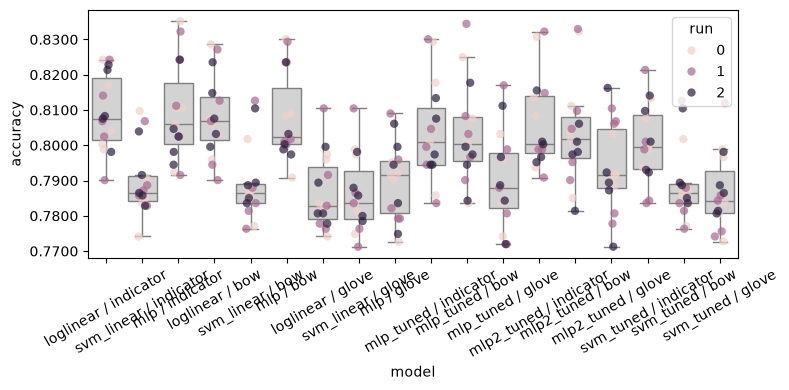

In [20]:
score_df = pd.DataFrame([{"model": f"{m} / {f}", "accuracy": a, "run": r, "fold": k}
                         for (m, f), arr in scores.items() if m in SYSTEMS
                         for r, row in enumerate(arr) for k, a in enumerate(row)])
analysis.plot_box_and_points(score_df)

### Pairwise comparison of the architectures (3 seeds)

In [21]:
arch_pairs = [("loglinear", "mlp_tuned"), ("loglinear", "mlp2_tuned"), ("loglinear", "svm_tuned"),
              ("mlp_tuned", "mlp2_tuned"), ("mlp_tuned", "svm_tuned"), ("mlp2_tuned", "svm_tuned")]
final_arch = table([{"features": f, **compare((a, f), (b, f), scores)} for f in FEATURES for a, b in arch_pairs])
final_arch.assign(A=final_arch.A.map(lambda x: x[0]), B=final_arch.B.map(lambda x: x[0]))

,features,A,B,mean A,mean B,diff (B-A),posterior std,P(A better),P(tie),P(B better),verdict (>0.9)
0,indicator,loglinear,mlp_tuned,0.8093,0.8039,-0.0055,0.0057,0.5325,0.4243,0.0432,undecided
1,indicator,loglinear,mlp2_tuned,0.8093,0.8060,-0.0034,0.0045,0.3621,0.5971,0.0409,undecided
2,indicator,loglinear,svm_tuned,0.8093,0.8008,-0.0085,0.0030,0.8699,0.1299,0.0002,undecided
3,indicator,mlp_tuned,mlp2_tuned,0.8039,0.8060,0.0021,0.0034,0.0271,0.7724,0.2005,undecided
4,indicator,mlp_tuned,svm_tuned,0.8039,0.8008,-0.0031,0.0047,0.3437,0.6003,0.0560,undecided
5,indicator,mlp2_tuned,svm_tuned,0.8060,0.8008,-0.0051,0.0044,0.5117,0.4691,0.0192,undecided
6,bow,loglinear,mlp_tuned,0.8081,0.8031,-0.0050,0.0052,0.5026,0.4601,0.0372,undecided
7,bow,loglinear,mlp2_tuned,0.8081,0.8034,-0.0047,0.0056,0.4788,0.4686,0.0527,undecided
8,bow,loglinear,svm_tuned,0.8081,0.7892,-0.0189,0.0037,0.9989,0.0011,0.0000,A better
9,bow,mlp_tuned,mlp2_tuned,0.8031,0.8034,0.0003,0.0024,0.0205,0.9447,0.0348,practically equivalent


### Comparison with the best system for different ROPE sizes

In [22]:
best_system = tuple(summary.iloc[0][["model", "features"]])
print("best system in cross-validation:", best_system)
rows = []
for m in SYSTEMS:
    for f in FEATURES:
        if (m, f) == best_system:
            continue
        row = {"system": f"{m} / {f}"}
        for rope in [0.0025, 0.005, 0.01]:
            r = compare(best_system, (m, f), scores, rope)
            row[f"diff"] = r["diff (B-A)"]
            row[f"P(best better) @{rope}"] = r["P(A better)"]
            row[f"P(tie) @{rope}"] = r["P(tie)"]
        rows.append(row)
pd.DataFrame(rows).sort_values("diff", ascending=False).round(3).reset_index(drop=True)

best system in cross-validation: ('loglinear', 'indicator')


,system,diff,P(best better) @0.0025,P(tie) @0.0025,P(best better) @0.005,P(tie) @0.005,P(best better) @0.01,P(tie) @0.01
0,mlp / indicator,0.000,0.332,0.336,0.195,0.610,0.049,0.902
1,loglinear / bow,-0.001,0.342,0.543,0.116,0.857,0.006,0.993
2,mlp / bow,-0.001,0.412,0.361,0.240,0.647,0.054,0.926
3,mlp2_tuned / indicator,-0.003,0.577,0.318,0.362,0.597,0.081,0.914
4,mlp_tuned / indicator,-0.005,0.696,0.213,0.532,0.424,0.219,0.773
5,mlp2_tuned / bow,-0.006,0.694,0.193,0.556,0.383,0.277,0.707
6,mlp_tuned / bow,-0.006,0.721,0.186,0.580,0.373,0.283,0.706
7,svm_tuned / indicator,-0.009,0.968,0.031,0.870,0.130,0.315,0.685
8,mlp2_tuned / glove,-0.016,0.919,0.050,0.875,0.107,0.735,0.259
9,mlp_tuned / glove,-0.019,0.977,0.017,0.957,0.039,0.874,0.125


For some systems the conclusion does not depend on the ROPE. The SVM with C=1 (and the tuned SVM on bag of words, which is the same model) and log-linear and the SVM on GloVe are worse than the best system even with a ROPE of 0.01 (P(best better) at least 0.94). The GloVe MLPs are clearly worse at 0.005 (P 0.88-0.98), but not all of them at 0.01.

Log-linear and the original MLP with indicators or bag of words, and the two-layer MLP with indicators, are within 0.001-0.003 of the best system. These comparisons are undecided at a ROPE of 0.005 (P(tie) 0.60-0.86) and practically equivalent at 0.01 (P(tie) 0.90-0.99). The tuned one-layer MLPs, the two-layer MLP on bag of words and the tuned SVM on indicators are 0.5-0.9 points below the best system and undecided at both.

Many comparisons are undecided at 0.005 because, with 3 seeds and 5 folds, the posterior standard deviation of a difference is about 0.004-0.006, as wide as the ROPE itself. Even if two systems have exactly the same mean, a large part of the posterior then falls outside the ROPE. To get P(tie) > 0.9 for a difference of zero, the posterior std would have to be below about 0.003 (0.005 / 1.645), which would need many more cross-validation runs. Undecided here means the experiment cannot resolve differences this small, not that the systems are different.

We keep 0.005 as our ROPE (section 2) and describe the results that depend on it as undecided at 0.005 and practically equivalent at 0.01.

## 9. Error analysis

Accuracy does not show which sentences a model gets wrong, whether it prefers one class, or how long it takes to train. In this section we train six systems once on all of train and look at their predictions on the validation split (872 whole sentences): log-linear, the tuned linear SVM, the tuned one-layer MLP and the tuned two-layer MLP on bag of words, and log-linear and the tuned MLP on GloVe, to see whether the dense representation makes different mistakes.

The settings are the same as in section 8, so the accuracies match the validation column there. Predictions and training times are cached in `results/xa_validation_predictions.json`.

In [23]:
import time
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

ERROR_SYSTEMS = [("loglinear", "bow"), ("svm_tuned", "bow"), ("mlp_tuned", "bow"), ("mlp2_tuned", "bow"),
                 ("loglinear", "glove"), ("mlp_tuned", "glove")]


def settings(name, f):
    if name == "loglinear": return {"max_iter": MAX_ITER}
    if name == "svm_tuned": return {"C": BEST_C[f]}
    return CHOSEN[(2 if name == "mlp2_tuned" else 1, f)]


def fit_predict(name, f):
    # train on all of train, predict the validation split; same settings as cv.eval_loglinear / eval_svm / eval_mlp
    start = time.time()
    if name in ("loglinear", "svm_tuned"):
        A, E = X[f], X_val[f]
        if SCALE[f]:
            scaler = StandardScaler().fit(A)
            A, E = scaler.transform(A), scaler.transform(E)
        model = (LogisticRegression(solver="saga", max_iter=MAX_ITER) if name == "loglinear"
                 else LinearSVC(C=BEST_C[f], max_iter=5000))
        pred = model.fit(A, y).predict(E)
    else:
        pred = []
        cv.eval_mlp(X[f], y, X_val[f], y_val, texts=raw_text, seed=0, scale=SCALE[f], predictions_out=pred, **settings(name, f))
    return np.asarray(pred, dtype=int), time.time() - start


pred_file = cv.RESULTS_DIR / "xa_validation_predictions.json"
saved_preds = {} if RECOMPUTE or not pred_file.exists() else json.loads(pred_file.read_text())
PRED, SECONDS = {}, {}
for name, f in ERROR_SYSTEMS:
    key = f"{name}/{f}"
    entry = saved_preds.get(key)
    if entry is None or entry["settings"] != json.loads(json.dumps(settings(name, f))):
        pred, seconds = fit_predict(name, f)
        entry = saved_preds[key] = {"settings": settings(name, f), "predictions": pred.tolist(), "seconds": seconds}
        pred_file.write_text(json.dumps(saved_preds))
    PRED[key], SECONDS[key] = np.array(entry["predictions"]), entry["seconds"]
print({k: round(float((p == y_val).mean()), 4) for k, p in PRED.items()})

{'loglinear/bow': 0.8108, 'svm_tuned/bow': 0.8222, 'mlp_tuned/bow': 0.8154, 'mlp2_tuned/bow': 0.828, 'loglinear/glove': 0.781, 'mlp_tuned/glove': 0.7752}


### Per-class accuracy

Train is 55.8% positive and validation 50.9%. A model that picked up the class balance of train would predict positive too often. "accuracy on negatives" is the share of negative sentences that is classified as negative, and the same for positives.

In [24]:
rows = []
for key, p in PRED.items():
    tn, fp, fn, tp = pd.crosstab(pd.Series(y_val, name="true"), pd.Series(p, name="predicted")).reindex(index=[0, 1], columns=[0, 1], fill_value=0).to_numpy().ravel()
    rows.append({"system": key, "accuracy": (tn + tp) / len(p), "accuracy on negatives": tn / (tn + fp),
                 "accuracy on positives": tp / (tp + fn), "predicted positive": p.mean(), "true positive share": y_val.mean(),
                 "TN": tn, "FP": fp, "FN": fn, "TP": tp})
pd.DataFrame(rows).round(4)

,system,accuracy,accuracy on negatives,accuracy on positives,predicted positive,true positive share,TN,FP,FN,TP
0,loglinear/bow,0.8108,0.7804,0.8401,0.5356,0.5092,334,94,71,373
1,svm_tuned/bow,0.8222,0.7804,0.8626,0.5470,0.5092,334,94,61,383
2,mlp_tuned/bow,0.8154,0.7944,0.8356,0.5264,0.5092,340,88,73,371
3,mlp2_tuned/bow,0.8280,0.7897,0.8649,0.5436,0.5092,338,90,60,384
4,loglinear/glove,0.7810,0.7430,0.8176,0.5424,0.5092,318,110,81,363
5,mlp_tuned/glove,0.7752,0.8107,0.7410,0.4702,0.5092,347,81,115,329


Five of the six systems lean towards positive. They predict positive for 53-55% of the sentences while 50.9% is positive, and they are 4-8 points more accurate on positive than on negative sentences (log-linear on bag of words: 0.84 vs 0.78). Most of their errors are negative reviews classified as positive: 88-110 false positives against 60-81 false negatives. This fits with the 56% positive train rows. The GloVe MLP is the exception and leans negative (47% predicted positive; 0.81 on negatives, 0.74 on positives). Since the validation split is balanced, accuracy is still a reasonable summary, but the errors are not symmetric.

### Accuracy per type of sentence

We mark validation sentences with simple rules on their NLTK tokens:

- negation: contains not, n't, no, never, nothing, none, nobody, neither, nor, without, hardly or barely
- contrast: contains but, yet, although, though, however or despite (the sentence often switches from one sentiment to the other)
- unknown word: contains at least one word that does not occur in train (stored as `[UNK]` for the word-level features)
- length: short (12 tokens or fewer), medium (13-25), long (more than 25)

A sentence can be in more than one group. The table shows the number of sentences per group and each system's accuracy on them.

In [25]:
NEGATION = {"not", "n't", "no", "never", "nothing", "none", "nobody", "neither", "nor", "without", "hardly", "barely"}
CONTRAST = {"but", "yet", "although", "though", "however", "despite"}
val_tokens = [list(t) for t in validation.tokens]
n_tok = np.array([len(t) for t in val_tokens])

GROUPS = {
    "all sentences": np.ones(len(y_val), bool),
    "negation": np.array([bool(NEGATION & set(t)) for t in val_tokens]),
    "no negation": np.array([not (NEGATION & set(t)) for t in val_tokens]),
    "contrast": np.array([bool(CONTRAST & set(t)) for t in val_tokens]),
    "no contrast": np.array([not (CONTRAST & set(t)) for t in val_tokens]),
    "unknown word": np.array(["[UNK]" in t for t in val_tokens]),      # the stored NLTK tokens mark unseen words as [UNK]
    "no unknown word": np.array(["[UNK]" not in t for t in val_tokens]),
    "short (<= 12 tokens)": n_tok <= 12,
    "medium (13-25)": (n_tok > 12) & (n_tok <= 25),
    "long (> 25)": n_tok > 25,
}
group_table = pd.DataFrame({key: {g: (p[m] == y_val[m]).mean() for g, m in GROUPS.items()} for key, p in PRED.items()})
group_table.insert(0, "sentences", {g: int(m.sum()) for g, m in GROUPS.items()})
group_table.round(3)

,sentences,loglinear/bow,svm_tuned/bow,mlp_tuned/bow,mlp2_tuned/bow,loglinear/glove,mlp_tuned/glove
all sentences,872,0.811,0.822,0.815,0.828,0.781,0.775
negation,200,0.725,0.755,0.725,0.760,0.680,0.655
no negation,672,0.836,0.842,0.842,0.848,0.811,0.811
contrast,141,0.738,0.752,0.752,0.738,0.709,0.681
no contrast,731,0.825,0.836,0.828,0.845,0.795,0.793
unknown word,511,0.798,0.814,0.806,0.828,0.787,0.775
no unknown word,361,0.828,0.834,0.828,0.828,0.773,0.776
short (<= 12 tokens),210,0.881,0.910,0.876,0.900,0.843,0.852
medium (13-25),437,0.817,0.810,0.801,0.824,0.771,0.769
long (> 25),225,0.733,0.764,0.787,0.769,0.742,0.716


A group of about 100 sentences has a standard error of about 4 accuracy points (sqrt(0.8 * 0.2 / 100)), so only large differences between groups mean something. The next table gives each difference with a 95% interval, for the tuned MLP on bag of words.

In [26]:
ref = PRED["mlp_tuned/bow"] == y_val
rows = []
for g, rest in [("negation", "no negation"), ("contrast", "no contrast"), ("unknown word", "no unknown word"),
                ("long (> 25)", "short (<= 12 tokens)")]:
    a, b = ref[GROUPS[g]], ref[GROUPS[rest]]
    diff = a.mean() - b.mean()
    se = np.sqrt(a.mean() * (1 - a.mean()) / len(a) + b.mean() * (1 - b.mean()) / len(b))
    rows.append({"group": g, "vs": rest, "accuracy": a.mean(), "accuracy (vs)": b.mean(), "gap": diff,
                 "95% interval": f"[{diff - 1.96 * se:+.3f}, {diff + 1.96 * se:+.3f}]"})
pd.DataFrame(rows).round(3)

,group,vs,accuracy,accuracy (vs),gap,95% interval
0,negation,no negation,0.725,0.842,-0.117,"[-0.185, -0.050]"
1,contrast,no contrast,0.752,0.828,-0.076,"[-0.152, +0.001]"
2,unknown word,no unknown word,0.806,0.828,-0.022,"[-0.074, +0.030]"
3,long (> 25),short (<= 12 tokens),0.787,0.876,-0.090,"[-0.159, -0.020]"


Negation, contrast and length make sentences harder; unknown words hardly do.

Negation occurs in 200 sentences (23%), and every system is 9-16 points less accurate on them; for the tuned MLP 0.725 vs 0.842, with a 95% interval of [-0.19, -0.05]. A bag-of-words model sees "not" as just another word with a fixed weight (see the weights below), so it cannot reverse the meaning of the word that is negated.

Sentences with a contrast word (141) are 8-11 points harder for every system. For the tuned MLP the interval just reaches zero ([-0.15, +0.00]), so with 141 sentences this is borderline. These sentences contain both sentiments, and the label depends on which part wins, which a bag of words cannot see.

Long sentences (more than 25 tokens) are 9-15 points harder than short ones for every system (tuned MLP: [-0.16, -0.02]). Long sentences often mix praise and criticism, while most training rows are short phrases.

511 sentences (59%) contain at least one unknown word, but the effect is small and not significant (tuned MLP: -2.2 points, [-0.07, +0.03]), and the two-layer MLP and the GloVe systems lose nothing on them. One unknown word in a sentence of 20 words rarely decides the sentiment.

### Overlap between the systems' errors

In [27]:
wrong = pd.DataFrame({k: p != y_val for k, p in PRED.items()})
n_wrong = wrong.sum(axis=1)
print(f"sentences every system gets right: {(n_wrong == 0).sum()} | every system gets wrong: {(n_wrong == len(PRED)).sum()} "
      f"| systems disagree: {((n_wrong > 0) & (n_wrong < len(PRED))).sum()} (of {len(y_val)})")
# share of sentences on which two systems disagree
keys = list(PRED)
pd.DataFrame([[np.mean(PRED[a] != PRED[b]) for b in keys] for a in keys], index=keys, columns=keys).round(3)

sentences every system gets right: 560 | every system gets wrong: 71 | systems disagree: 241 (of 872)


,loglinear/bow,svm_tuned/bow,mlp_tuned/bow,mlp2_tuned/bow,loglinear/glove,mlp_tuned/glove
loglinear/bow,0.000,0.064,0.076,0.081,0.177,0.173
svm_tuned/bow,0.064,0.000,0.110,0.084,0.177,0.180
mlp_tuned/bow,0.076,0.110,0.000,0.070,0.167,0.171
mlp2_tuned/bow,0.081,0.084,0.070,0.000,0.162,0.174
loglinear/glove,0.177,0.177,0.167,0.162,0.000,0.077
mlp_tuned/glove,0.173,0.180,0.171,0.174,0.077,0.000


In [28]:
pd.set_option("display.max_colwidth", 160)
show = lambda mask, n=10: (validation.assign(label=np.where(y_val == 1, "positive", "negative"))
                           .loc[mask, ["text", "label"]].sample(min(n, int(mask.sum())), random_state=0))
print("Wrong for every system:")
display(show((n_wrong == len(PRED)).to_numpy()))
print("Tuned MLP (bow) right, log-linear (bow) wrong:")
display(show(((PRED["mlp_tuned/bow"] == y_val) & (PRED["loglinear/bow"] != y_val)), 6))
print("Log-linear (bow) right, tuned MLP (bow) wrong:")
display(show(((PRED["loglinear/bow"] == y_val) & (PRED["mlp_tuned/bow"] != y_val)), 6))

Wrong for every system:


,text,label
292,the story and the friendship proceeds in such a way that you 're watching a soap opera rather than a chronicle of the ups and downs that accompany lifelong ...,negative
301,"the x potion gives the quickly named blossom , bubbles and buttercup supernatural powers that include extraordinary strength and laser-beam eyes , which unf...",negative
617,"the so-inept - it 's - surreal dubbing ( featuring the voices of glenn close , regis philbin and breckin meyer ) brings back memories of cheesy old godzilla...",negative
235,"whether you like rap music or loathe it , you ca n't deny either the tragic loss of two young men in the prime of their talent or the power of this movie .",positive
358,( d ) oes n't bother being as cloying or preachy as equivalent evangelical christian movies -- maybe the filmmakers know that the likely audience will alrea...,positive
656,"so much facile technique , such cute ideas , so little movie .",positive
88,fresnadillo 's dark and jolting images have a way of plying into your subconscious like the nightmare you had a week ago that wo n't go away .,positive
749,a working class `` us vs. them `` opera that leaves no heartstring untugged and no liberal cause unplundered .,positive
402,"however it may please those who love movies that blare with pop songs , young science fiction fans will stomp away in disgust .",negative
865,"mcconaughey 's fun to watch , the dragons are okay , not much fire in the script .",positive


Tuned MLP (bow) right, log-linear (bow) wrong:


,text,label
700,"is the time really ripe for a warmed-over james bond adventure , with a village idiot as the 007 clone ?",negative
582,"despite all evidence to the contrary , this clunker has somehow managed to pose as an actual feature movie , the kind that charges full admission and gets h...",negative
536,"a disappointment for those who love alternate versions of the bard , particularly ones that involve deep fryers and hamburgers .",negative
691,"an effectively creepy , fear-inducing ( not fear-reducing ) film from japanese director hideo nakata , who takes the superstitious curse on chain letters an...",positive
606,makes for a pretty unpleasant viewing experience .,negative
526,it 's a bit disappointing that it only manages to be decent instead of dead brilliant .,negative


Log-linear (bow) right, tuned MLP (bow) wrong:


,text,label
70,"for all its impressive craftsmanship , and despite an overbearing series of third-act crescendos , lily chou-chou never really builds up a head of emotional...",negative
832,manages to show life in all of its banality when the intention is quite the opposite .,negative
306,the story and structure are well-honed .,positive
187,` de niro ... is a veritable source of sincere passion that this hollywood contrivance orbits around . ',positive
750,"nelson 's brutally unsentimental approach ... sucks the humanity from the film , leaving behind an horrific but weirdly unemotional spectacle .",negative
741,but it still jingles in the pocket .,positive


Which sentences go wrong depends mostly on the representation and much less on the architecture. 560 sentences are classified correctly by all six systems and 71 are wrong for all of them. The four bag-of-words systems disagree with each other on only 6-11% of the sentences and the two GloVe systems on 8%, while a sparse and a GloVe system disagree on 16-18%. Combining a sparse and a GloVe model would therefore probably help more than a deeper MLP.

The sentences that every system gets wrong are mostly mixed or ironic. Some give praise and then a reservation or the other way around ("mcconaughey 's fun to watch , the dragons are okay , not much fire in the script", labelled positive), some are sarcastic ("leaves no heartstring untugged and no liberal cause unplundered"), and some express sentiment through images instead of opinion words ("dark and jolting images ... like the nightmare you had a week ago", positive). For a few of them the label itself is debatable, since SST labels are averaged ratings from crowd workers. Where the MLP and log-linear disagree (6-8% of the sentences) we did not find a clear pattern, which fits with their equal accuracy.

### Log-linear weights

The weights of the bag-of-words log-linear model (trained on all of train) show which words push a sentence towards positive or negative, and how negation is handled: not, n't and no each get a single weight, regardless of the word they negate.

In [29]:
loglin = LogisticRegression(solver="saga", max_iter=MAX_ITER).fit(X["bow"], y)
id_to_word = {i: w for w, i in tokenizer.get_vocab().items()}
weights = pd.Series(loglin.coef_[0], index=[id_to_word[i] for i in range(len(loglin.coef_[0]))])
display(pd.DataFrame({"most positive": weights.nlargest(15).index, "weight +": weights.nlargest(15).values.round(2),
                      "most negative": weights.nsmallest(15).index, "weight -": weights.nsmallest(15).values.round(2)}))
weights[["not", "n't", "no", "never", "but", "good", "bad", "funny", "boring"]].round(2).to_frame("weight")

,most positive,weight +,most negative,weight -
0,refreshing,3.56,lacking,-4.45
1,remarkable,3.55,lacks,-4.15
2,powerful,3.32,worst,-4.07
3,hilarious,3.25,devoid,-3.82
4,beautiful,3.07,failure,-3.80
5,prose,3.07,mess,-3.78
6,wonderful,3.06,stupid,-3.44
7,terrific,2.98,bore,-3.39
8,treat,2.95,loses,-3.30
9,appealing,2.92,flat,-3.28


,weight
not,-1.83
n't,-2.21
no,-2.19
never,-0.34
but,-0.00
good,1.93
bad,-2.75
funny,1.60
boring,-2.32


The words with the largest weights are the opinion words you would expect (refreshing, remarkable, hilarious and lacking, worst, mess). A few weights explain the errors above.

"half-bad" is one of the most positive words. It occurs in only 5 train rows (2 sentences and their sub-phrases), always as "not half-bad" and labelled positive, so the model learned the negated phrase as a positive word. Because of the repeated sub-phrases, these 2 sentences also count 5 times.

The negations not, n't and no each get a fixed negative weight (-1.8 to -2.2), whatever they negate. "Not bad" is scored as bad (-2.75) plus another -1.8, so very negative, which is the opposite of what it means.

"but" gets a weight of 0, because 53.7% of the train rows containing it are positive, close to the overall share. So the model cannot use the word that tells which part of the sentence matters.

### Training time

Seconds to train each system once on all 67k train rows on a laptop CPU (for the MLPs this includes evaluating the inner slice after every epoch). The exact numbers depend on the machine and on what else was running, so only the order of magnitude matters.

In [30]:
pd.DataFrame({"seconds to train on all of train": SECONDS}).round(1)

,seconds to train on all of train
loglinear/bow,16.9
svm_tuned/bow,11.2
mlp_tuned/bow,62.8
mlp2_tuned/bow,82.7
loglinear/glove,21.2
mlp_tuned/glove,40.1


The linear models train in 11-21 s and the MLPs in 40-83 s, with the two-layer MLP the slowest, so the MLPs take about 3 to 7 times longer without being more accurate in cross-validation. Another notebook was running at the same time, so the absolute times are too high, but the ratios should be about right.

### Fixed bug: unknown words in the GloVe features

`data/tokenized/nltk/` stores the tokens of each sentence after the word-level tokenizer, so a word that does not occur in train is stored as `[UNK]`. Originally `cv_helpers.build_features("glove")` averaged the GloVe vectors of these stored tokens. `[UNK]` has no GloVe vector and was skipped, so the unknown words never reached GloVe, although it knows 85% of them (see `data_analysis.ipynb`).

Cross-validation was not affected: the vocabulary was built from all of train, so the train rows contain no `[UNK]` (the stored tokens and the raw words are identical for all 67,349 rows). The validation split was affected: 5.7% of its tokens, in 511 of the 872 sentences, were left out of the GloVe average.

`build_features` now averages the raw words (the `text` column), and all GloVe validation results in all notebooks were recomputed. The cell below shows the effect for two models, with the old (stored tokens) and the fixed (raw words) validation features.

In [31]:
import embeddings
word_to_row, glove = embeddings.load_glove()
val_stored = validation.tokens
print(f"validation tokens stored as [UNK]: {sum(list(t).count('[UNK]') for t in val_stored)} "
      f"in {sum('[UNK]' in list(t) for t in val_stored)} sentences")
X_val_before = embeddings.average_embeddings(val_stored, word_to_row, glove)   # what the original code used
pd.DataFrame([{"model": name,
               "validation, before the fix": fit(X["glove"], y, X_val_before, y_val),
               "validation, after the fix": fit(X["glove"], y, X_val["glove"], y_val)}
              for name, fit in [("loglinear", lambda A, b, E, e: cv.eval_loglinear(A, b, E, e, MAX_ITER, scale=True)),
                                ("svm C=1", lambda A, b, E, e: cv.eval_svm(A, b, E, e, kernel="linear", C=1.0, scale=True))]]
             ).assign(difference=lambda d: d.iloc[:, 2] - d.iloc[:, 1]).round(4)

validation tokens stored as [UNK]: 972 in 511 sentences


,model,"validation, before the fix","validation, after the fix",difference
0,loglinear,0.7729,0.7810,0.0080
1,svm C=1,0.7718,0.7821,0.0103


The fix improves GloVe's validation accuracy by about one point. GloVe is still below the sparse features on validation, so none of the conclusions change.

### Conclusions

Log-linear with token indicators (NLTK tokens) has the highest cross-validated accuracy, 0.809 over 3 seeds and 5 parent folds. However, it is not clearly better than the original MLP (indicators or bag of words), log-linear with bag of words, or the two-layer MLP with indicators. All of these are within 0.003 of it: undecided at a ROPE of 0.005 and practically equivalent at 0.01. Since they perform the same, we choose log-linear with token indicators: it is the simplest model, about 4 times faster to train than the MLP, and its weights can be read directly.

On the validation split the original and two-layer MLPs score highest (0.821-0.829, against 0.814 for log-linear). That is a single split of 872 sentences, though, where 1.5 points is 13 sentences and the standard error of an accuracy is about 1.3 points, so we do not base the choice on it.

Architectures: log-linear, the MLP and the two-layer MLP perform about the same, and tuning the MLP's learning rate and size did not help (section 4). The linear SVM with C=1 is about 2 points worse because it overfits the training folds (section 5); tuning C closes about half of that gap on indicators but not on bag of words. The non-linearity does not add anything here. With sparse word features and this amount of data the task seems close to linearly separable, and the remaining errors (negation, contrast, mixed sentences) depend on word order, which none of these models sees.

Representations: indicators and bag of words score the same everywhere, because counts above 1 are almost only function words (`data_analysis.ipynb`). Averaged GloVe is about 2 points worse for every architecture in cross-validation and 3 points worse on validation for log-linear (0.781 vs 0.814), but it makes different mistakes than the sparse features.

Evaluation: the parent folds are necessary, since random folds inflate accuracy to about 0.90 (per-model notebooks). Using three seeds instead of one does not change the differences but gives more reliable posterior widths. Building the tokenizers on all of train has no measurable effect (section 6). Part of the remaining gap between cross-validation and validation comes from the validation sentences being slightly easier (section 5).

Errors: the main sources of errors are negation (-12 points), long and mixed sentences (-9 to -15), contrast (about -8) and a slight bias towards positive, inherited from the 56% positive train rows. Unknown words matter little. All of this suggests that the next step is features that take word order into account (n-grams, or the sequence models in the later projects), not a bigger model on top of a bag of words.